# Projet prediction du churn (bank customer churn)

In [ ]:
# import de données: Bank Customer Churn Modelling from: https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling
#Cet ensemble de données contient des informations sur les clients d'une banque, 
#et la variable cible est une variable binaire indiquant si le client a quitté la banque (fermé son compte) 
#ou s'il continue d'être client.

import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/shrutimechlearn/Churn-Modelling/master/Churn_Modelling.csv")
df.head()

ModuleNotFoundError: No module named 'pandas'

| Variable        | Description           |
| --------------- | --------------------- |
| CreditScore     | score de crédit       |
| Geography       | pays                  |
| Gender          | sexe                  |
| Age             | âge                   |
| Tenure          | ancienneté            |
| Balance         | solde                 |
| NumOfProducts   | nb de produits        |
| HasCrCard       | carte bancaire        |
| IsActiveMember  | activité              |
| EstimatedSalary | salaire               |
| Exited          | target (1 = churn) |


Supprime les colonnes inutiles :

In [ ]:
df = df.drop(["RowNumber", "CustomerId", "Surname"], axis=1)

In [ ]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# EDA

In [ ]:
df.info()
df.describe()

NameError: name 'df' is not defined

un base de données de 10.000 lignes et 11 colonnes

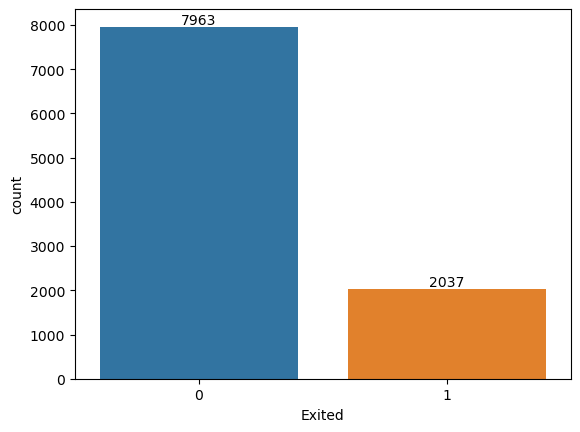

In [ ]:
# Representation de la variable à prédire pour voir la proportion des occurrences
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(x='Exited', data=df)

# ajout des etiquettes
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}', 
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom'
    )

plt.show()

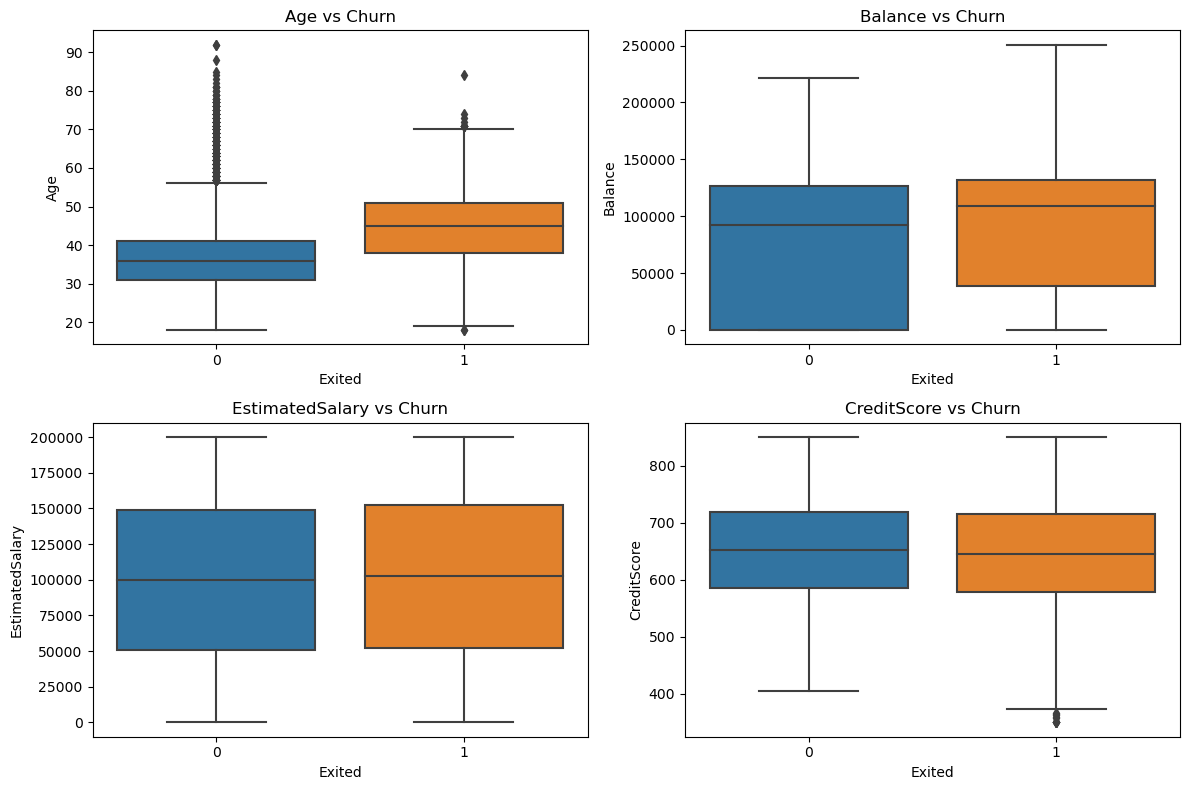

In [ ]:
# analyse par boxplots
plt.figure(figsize=(12,8))

for i, var in enumerate(['Age', 'Balance', 'EstimatedSalary', 'CreditScore']):
    plt.subplot(2,2,i+1)
    sns.boxplot(x='Exited', y=var, data=df)
    plt.title(f"{var} vs Churn")

plt.tight_layout()
plt.show()

L’analyse exploratoire à travers les boxplots montre que Les clients plus âgés ont un risque de churn plus élevé 
et détiennent en moyenne un solde plus élevé. 
En revanche, le salaire et le score de crédit n’apparaissent pas comme des facteurs discriminants majeurs

In [ ]:
df["Exited"].value_counts(normalize=True)

0    0.7963
1    0.2037
Name: Exited, dtype: float64

# Feature engineering: construction de nouvelles variables

In [ ]:
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["AgeGroup"] = pd.cut(df["Age"], bins=[18,30,40,50,60,100])
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio,AgeGroup
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,"(40, 50]"
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744670,"(40, 50]"
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.401362,"(40, 50]"
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.000000,"(30, 40]"
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587035,"(40, 50]"


Quelques nettoyages

In [ ]:
df = df.dropna()

Encodage

In [ ]:
df = pd.get_dummies(df, drop_first=True)

Normalisation

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('Exited', axis=1))

Train / Test split

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('Exited', axis=1) # variables exogenes
y = df['Exited'] # variable endogene( target)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Modélisation

## Régression logistique

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

Évaluation

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.96      0.90      1600
           1       0.64      0.29      0.40       396

    accuracy                           0.83      1996
   macro avg       0.74      0.62      0.65      1996
weighted avg       0.80      0.83      0.80      1996

[[1537   63]
 [ 283  113]]


## Gérer le déséquilibre 

In [ ]:
from imblearn.over_sampling import SMOTE

sm = SMOTE()
X_res, y_res = sm.fit_resample(X_train, y_train)

## Optimisation (Hyperparameters)

In [ ]:
from sklearn.model_selection import GridSearchCV

params = {'C': [0.1, 1, 10]}

grid = GridSearchCV(LogisticRegression(), params, cv=5)
grid.fit(X_train, y_train)

print(grid.best_params_)

{'C': 0.1}


Interprétation : Comprendre pourquoi un client part

In [ ]:
import numpy as np

coefficients = pd.DataFrame({
    "feature": X.columns,
    "importance": model.coef_[0]
}).sort_values(by="importance", ascending=False)

print(coefficients)

               feature  importance
1                  Age    0.591811
14   AgeGroup_(50, 60]    0.390293
13   AgeGroup_(40, 50]    0.385024
9    Geography_Germany    0.329010
3              Balance    0.168391
8   BalanceSalaryRatio    0.069446
7      EstimatedSalary    0.048170
12   AgeGroup_(30, 40]    0.039671
10     Geography_Spain    0.010008
5            HasCrCard   -0.019808
4        NumOfProducts   -0.059896
0          CreditScore   -0.066481
2               Tenure   -0.066530
15  AgeGroup_(60, 100]   -0.105852
11         Gender_Male   -0.273787
6       IsActiveMember   -0.483022


| Feature                | Coefficient | Interprétation                                                                                                                     |
| ---------------------- | ----------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **Age**                | 0.5918      | Plus le client est âgé → plus il risque de partir. L’âge est le facteur le plus influent.                                          |
| **AgeGroup_(50,60]**   | 0.3903      | Les clients de 50-60 ans sont plus susceptibles de churn par rapport à la référence (<30 ans).                                     |
| **AgeGroup_(40,50]**   | 0.3850      | Même logique pour 40-50 ans.                                                                                                       |
| **Geography_Germany**  | 0.3290      | Les clients allemands ont plus de risque de churn que ceux du pays de référence (probablement France).                             |
| **Balance**            | 0.1684      | Plus le solde du compte est élevé → risque de churn légèrement plus élevé. Peut indiquer que les clients riches sont plus mobiles. |
| **BalanceSalaryRatio** | 0.0694      | Ratio solde/salaire positif → léger impact sur churn.                                                                              |
| **EstimatedSalary**    | 0.0482      | Salaire plus élevé → très léger effet d’augmentation du churn.                                                                     |
| **AgeGroup_(30,40]**   | 0.0397      | Peu d’impact, mais légèrement plus de churn que référence.                                                                         |
| **Geography_Spain**    | 0.0100      | Presque neutre.                                                                                                                    |
| **HasCrCard**          | -0.0198     | Avoir une carte bancaire → très léger effet protecteur.                                                                            |
| **NumOfProducts**      | -0.0599     | Plus de produits → moins de chance de churn (fidélisation).                                                                        |
| **CreditScore**        | -0.0665     | Score élevé → client moins à risque.                                                                                               |
| **Tenure**             | -0.0665     | Ancienneté → réduit légèrement le churn.                                                                                           |
| **AgeGroup_(60,100]**  | -0.1059     | Les clients très âgés (>60) sont légèrement moins susceptibles de churn par rapport à la catégorie <30 ans.                        |
| **Gender_Male**        | -0.2738     | Les hommes ont moins tendance à churn que les femmes.                                                                              |
| **IsActiveMember**     | -0.4830     | Facteur protecteur majeur : un client actif est beaucoup moins susceptible de partir.                                              |


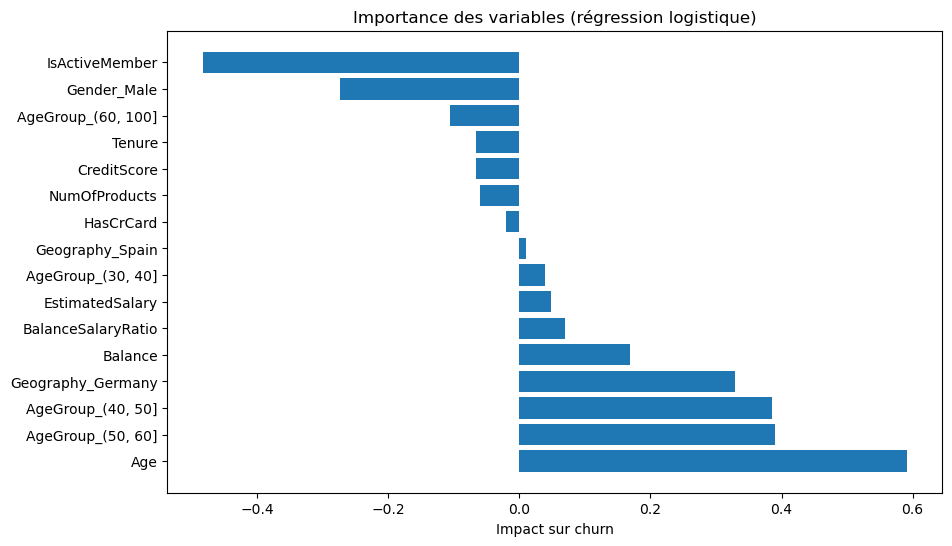

In [ ]:
import matplotlib.pyplot as plt

coef_df = pd.DataFrame({
    'feature': X.columns,
    'importance': model.coef_[0]
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(coef_df['feature'], coef_df['importance'])
plt.xlabel("Impact sur churn")
plt.title("Importance des variables (régression logistique)")
plt.show()

## Avec la regression logistique:
## Ce qui retient les clients (Impact Négatif sur le Churn)

Les barres vers la gauche indiquent les facteurs qui diminuent la probabilité de départ :

IsActiveMember (Le plus fort) : C'est le facteur de rétention n°1. Un client actif est beaucoup moins susceptible de partir.

Gender_Male : Les hommes semblent avoir une probabilité de départ plus faible que les femmes dans ce jeu de données.

AgeGroup (60, 100] : Étonnamment, les clients très seniors (plus de 60 ans) sont plus stables.

NumOfProducts : Plus un client possède de produits, moins il part (effet de "sticky business").

## Ce qui provoque le départ (Impact Positif sur le Churn)

Les barres vers la droite indiquent les facteurs qui augmentent la probabilité de départ :

Age (Le plus fort) : De manière générale, plus l'âge augmente, plus le risque de churn s'élève, avec des pics très marqués pour les tranches [40, 50] et [50, 60].

Geography_Germany : Être un client en Allemagne est un fort prédicteur de départ par rapport aux autres pays.

Balance : Un solde élevé est corrélé à un risque de départ plus important (ce qui est souvent contre-intuitif, mais fréquent si ces clients cherchent de meilleurs placements ailleurs).

Calcul de la ROC et AUC

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilité de churn (classe 1)
y_proba = model.predict_proba(X_test)[:,1]

# Calcul FPR, TPR et seuils
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Calcul AUC
roc_auc = auc(fpr, tpr)

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilité de churn (classe 1)
y_proba = model.predict_proba(X_test)[:,1]

# Calcul FPR, TPR et seuils
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Calcul AUC
roc_auc = auc(fpr, tpr)

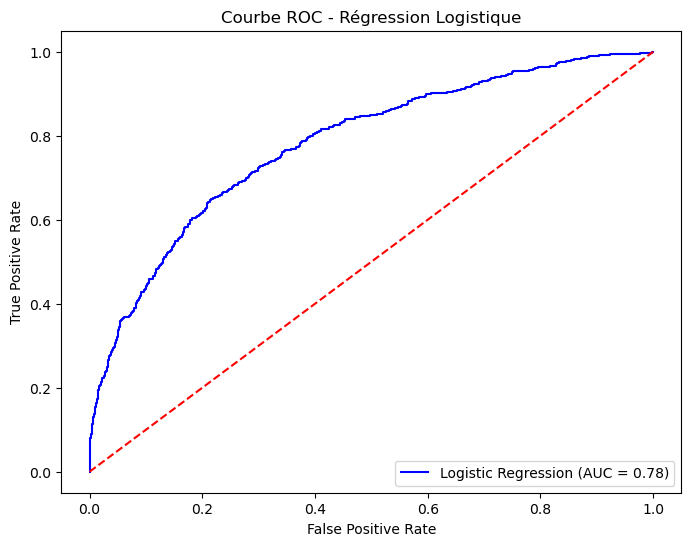

In [ ]:
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', label=f'Logistic Regression (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color='red', linestyle='--')  # ligne diagonale = hasard
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - Régression Logistique')
plt.legend(loc='lower right')
plt.show()

## Préprocessing avancé (propre et scalable)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = X.select_dtypes(include=['int64', 'float64']).columns # Les colonnes numeriques
cat_cols = X.select_dtypes(include=['object']).columns # les colonnes categorielles

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index([], dtype='object'))])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        n_estimators=200, random_state=42))])

## XGBoost

In [ ]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight= (len(y_train) / sum(y_train)),
        random_state=42
    ))
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index([], dtype='object'))])),
                ('model',
                 XGBClassifier(base_score=None, booster=...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
     

## Évaluation 

In [ ]:
from sklearn.metrics import roc_auc_score, classification_report

def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]
    
    print(classification_report(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, y_proba))

print("Random Forest")
evaluate(rf_pipeline, X_test, y_test)

print("\nXGBoost")
evaluate(xgb_pipeline, X_test, y_test)

Random Forest
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1589
           1       0.54      0.63      0.58       407

    accuracy                           0.82      1996
   macro avg       0.72      0.75      0.73      1996
weighted avg       0.83      0.82      0.82      1996

ROC-AUC: 0.8390964910788699

XGBoost
              precision    recall  f1-score   support

           0       0.91      0.82      0.86      1589
           1       0.49      0.67      0.57       407

    accuracy                           0.79      1996
   macro avg       0.70      0.75      0.71      1996
weighted avg       0.82      0.79      0.80      1996

ROC-AUC: 0.8334572916070714


Feature importance
Random Forest

In [ ]:
importances = rf_pipeline.named_steps['model'].feature_importances_

In [ ]:
importances

array([0.08179601, 0.33993574, 0.04739141, 0.08853597, 0.21823139,
       0.01066667, 0.06057783, 0.08043215, 0.07243283])

XGBoost

In [ ]:
importances = xgb_pipeline.named_steps['model'].feature_importances_
importances

array([0.05344491, 0.14051987, 0.04485572, 0.06359328, 0.38397714,
       0.04371345, 0.1512209 , 0.05201387, 0.06666084], dtype=float32)

## Explicabilité avec SHAP 

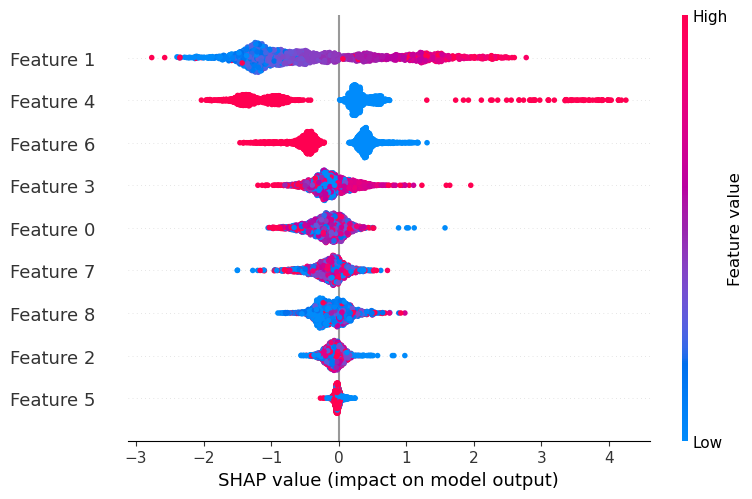

In [ ]:
import shap

model = xgb_pipeline.named_steps['model']
explainer = shap.TreeExplainer(model)

X_transformed = xgb_pipeline.named_steps['prep'].transform(X_test)

shap_values = explainer.shap_values(X_transformed)

shap.summary_plot(shap_values, X_transformed)

J’utilise SHAP pour interpréter mes modèles XGBoost et Random Forest. 
Cela me permet d’identifier non seulement les variables importantes, mais aussi leur impact directionnel sur le churn. 
exemple, un âge élevé augmente la probabilité de churn, tandis que l’activité client la réduit fortement.

## Extraire l’importance des variables Pour Random Forest

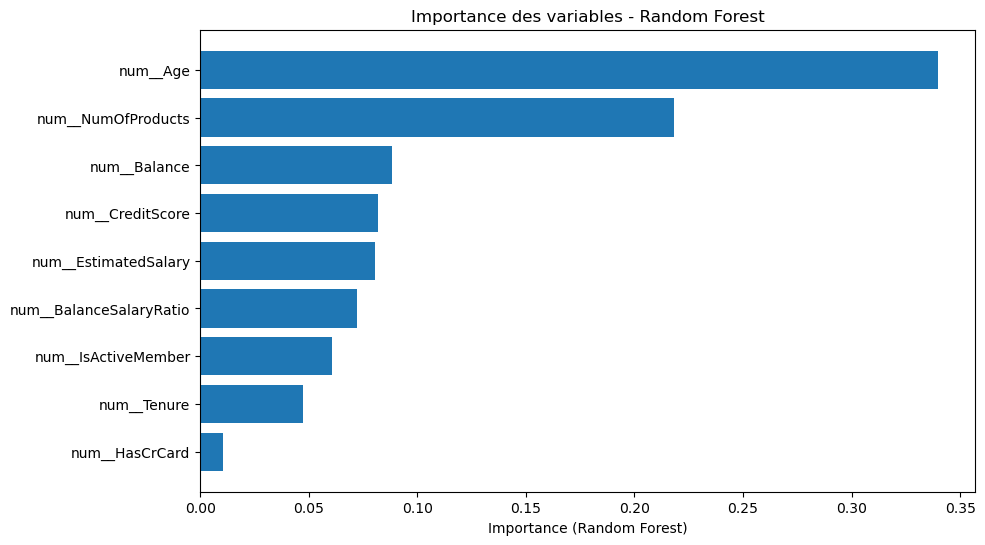

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extraire l'étape du modèle du pipeline
rf_model = rf_pipeline.named_steps['model']

# Récupérer les features après preprocessing
# Attention si tu as OneHotEncoder
feature_names = rf_pipeline.named_steps['prep'].get_feature_names_out()

# Importance
rf_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values(by='importance', ascending=False)

# Affichage
plt.figure(figsize=(10,6))
plt.barh(rf_importance['feature'], rf_importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance (Random Forest)")
plt.title("Importance des variables - Random Forest")
plt.show()

## Pour XGBoost

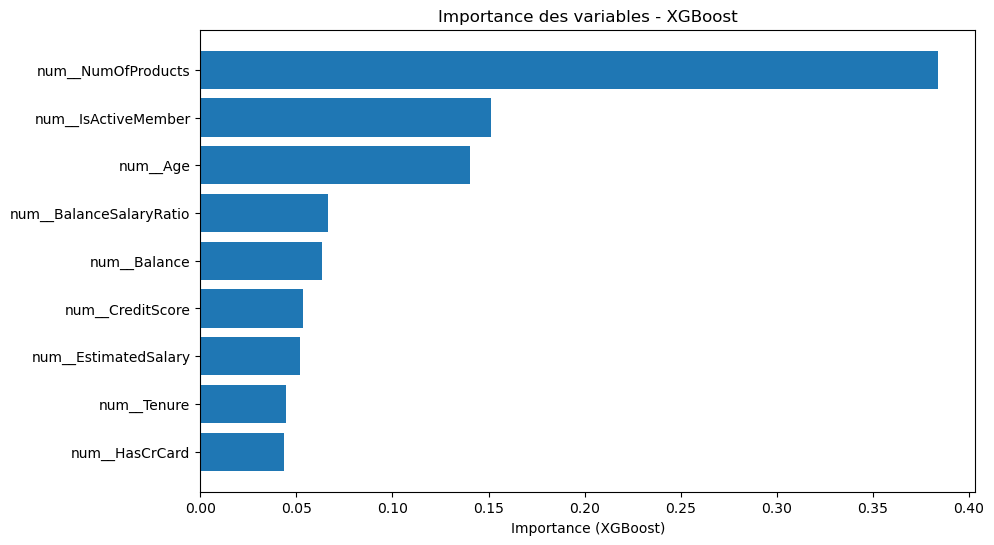

In [ ]:
xgb_model = xgb_pipeline.named_steps['model']

xgb_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': xgb_model.feature_importances_
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(xgb_importance['feature'], xgb_importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance (XGBoost)")
plt.title("Importance des variables - XGBoost")
plt.show()

## interpretation:
Les deux modèles s'accordent sur le fait que trois variables dominent largement le pouvoir prédictif :

num__NumOfProducts (Nombre de produits) : C'est un prédicteur majeur pour les deux. Cela suggère que la fidélité est fortement liée à la profondeur de la relation bancaire.

num__Age : L'âge est un facteur clé, particulièrement crucial pour le Random Forest.

num__IsActiveMember : Le fait d'être un membre actif est déterminant, surtout pour XGBoost.
    
## Interpretation metiers
    
 Ciblez l'engagement : Le comportement (nombre de produits possédés et activité réelle du client) est le meilleur indicateur de risque ou de fidélité.

Surveillez les tranches d'âge : Il existe probablement des "âges critiques" où le comportement des clients change radicalement.

Inutile de trop se focaliser sur la carte de crédit : Que le client possède ou non une carte de crédit ne semble pas aider à prédire son comportement futur dans ce jeu de données spécifique.

## Courbe de ROC pour comparer les modèles

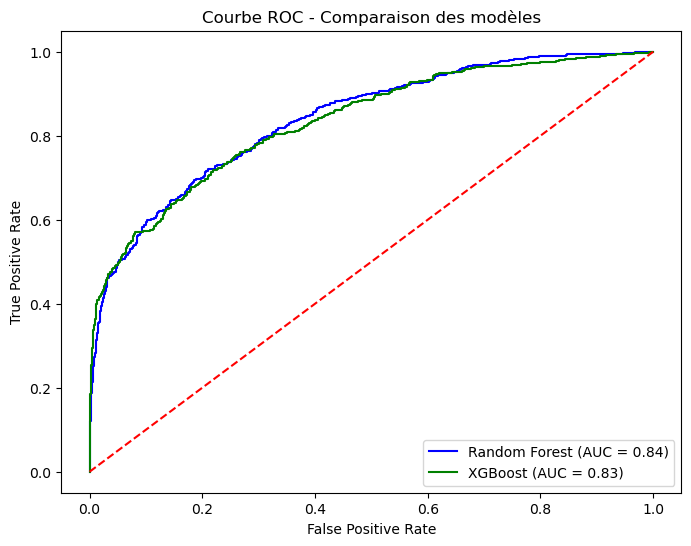

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilités pour la classe positive
y_rf_proba = rf_pipeline.predict_proba(X_test)[:,1]
y_xgb_proba = xgb_pipeline.predict_proba(X_test)[:,1]

# Calcul ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_rf_proba)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_xgb_proba)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr_rf, tpr_rf, color='blue', label=f'Random Forest (AUC = {roc_auc_rf:.2f})')
plt.plot(fpr_xgb, tpr_xgb, color='green', label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')
plt.plot([0,1],[0,1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - Comparaison des modèles')
plt.legend(loc='lower right')
plt.show()

## Analyse globale
Pour réduire le churn, les modèles suggèrent trois leviers prioritaires :

Réactiver les membres passifs (l'impact de IsActiveMember est massif).

Cibler spécifiquement les 40-60 ans (zone de danger maximale).

Analyser le marché allemand (pour comprendre pourquoi les clients y partent plus qu'ailleurs).